# Background shortcut generation

Importing the required libraries

In [63]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets
from typing import Any, Tuple
from numpy.typing import NDArray

Loading the YAML configuration file

In [64]:
with open("../configs/experiment.yaml", "r") as file:
    config = yaml.safe_load(file)

Loading the Fashion-MNIST training dataset

In [65]:
DATA_DIR = f"../{config['dataset_param']['data_dir']}"
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)
if os.path.exists(DATA_DIR):
    try:
        print(f"Dataset found: Loading the dataset from {DATA_DIR}")
        dataset = datasets.FashionMNIST(root=DATA_DIR, train=True, download=False)
    except RuntimeError as e:
        print("Error Dataset not found, downloading the dataset")
        dataset = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)

Dataset found: Loading the dataset from ../data


### Controlled colour-label relationship

Assigning a distinct synthetic colour to each of the ten clothing classes.


| Clothing class | Assigned training cue |
|---|---|
| T-shirt/top | Red |
| Trouser | Blue |
| Pullover | Green |
| Dress | Yellow |
| Coat | Purple |
| Sandal | Orange |
| Shirt | Cyan |
| Sneaker | Pink |
| Bag | Teal |
| Ankle boot | Brown |

### Approach: Colour only near-zero-valued pixels

In [ ]:
CLASS_NAMES = dataset.classes
CLASS_COLORS = np.array(
    config["shortcut_generation_param"]["class_colors"],
    dtype=np.uint8,
)
NEAR_ZERO_INTENSITY_THRESHOLD = config["shortcut_generation_param"][
    "near_zero_intensity_threshold"
]

In [ ]:
def inject_background_cue(
    grayscale_image: NDArray[Any],
    label: Any,
    class_colors_array: NDArray[np.unsignedinteger],
    near_zero_intensity_threshold: Any,
) -> Tuple[NDArray[Any], Any]:

    rgb_image = np.stack([grayscale_image] * 3, axis=-1)
    near_zero_intensity_mask = grayscale_image < NEAR_ZERO_INTENSITY_THRESHOLD
    rgb_image[near_zero_intensity_mask] = CLASS_COLORS[label]

    return rgb_image, label

In [ ]:
grayscale_image, label = dataset[1]
grayscale_image = np.array(grayscale_image)
rgb_image, label = inject_background_cue(
    grayscale_image, label, CLASS_COLORS, NEAR_ZERO_INTENSITY_THRESHOLD
)

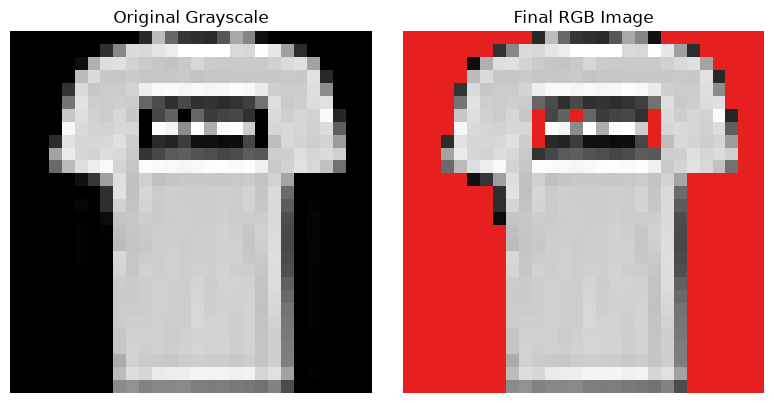

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Display the original grayscale image
axes[0].imshow(grayscale_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

# # Display the mask image
# axes[1].imshow(near_zero_intensity_mask)
# axes[1].set_title("Mask of Near-Zero-Intensity Pixels")
# axes[1].axis("off")

# Display the final RGB image
axes[1].imshow(rgb_image)
axes[1].set_title("Final RGB Image")
axes[1].axis("off")

# Render the plot on screen
plt.tight_layout()
plt.show()

### Background Transformation Validation

In [70]:
print(f"Original Grayscale Image Shape: {grayscale_image.shape}")
print(f"RGB Image Shape: {rgb_image.shape}")

Original Grayscale Image Shape: (28, 28)
RGB Image Shape: (28, 28, 3)


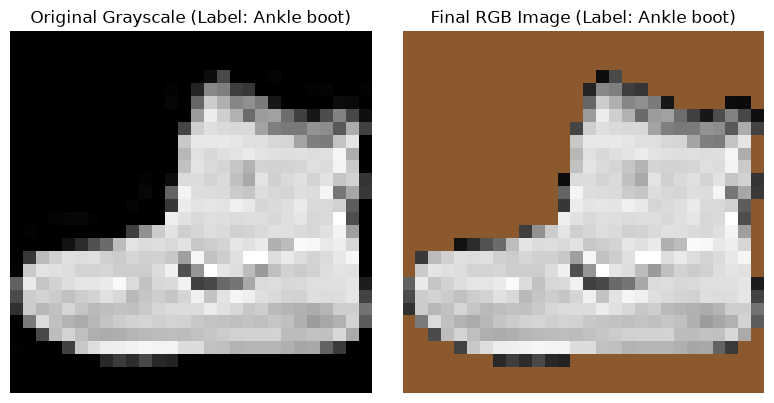

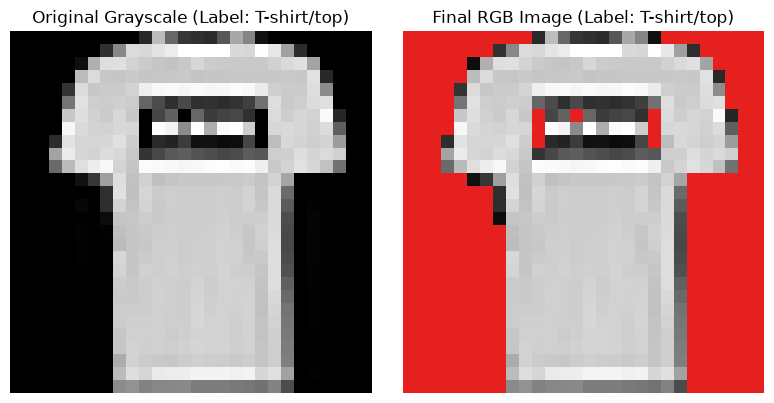

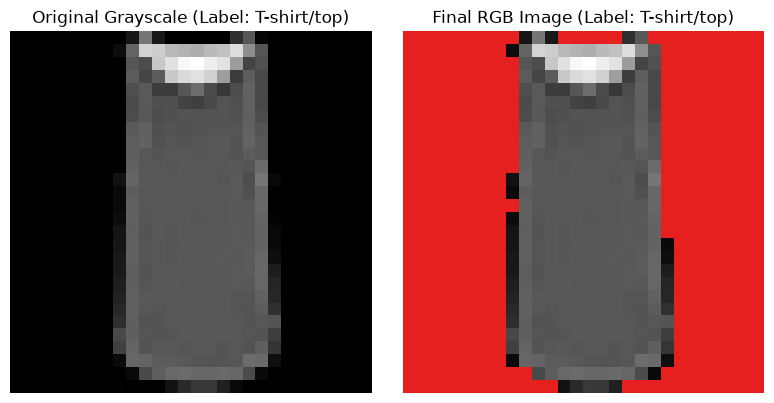

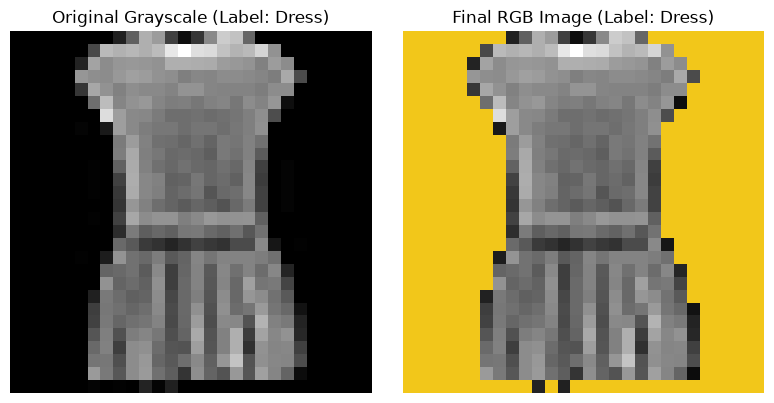

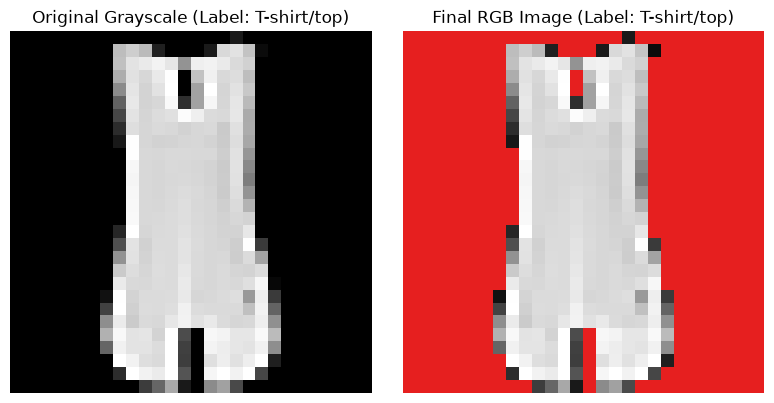

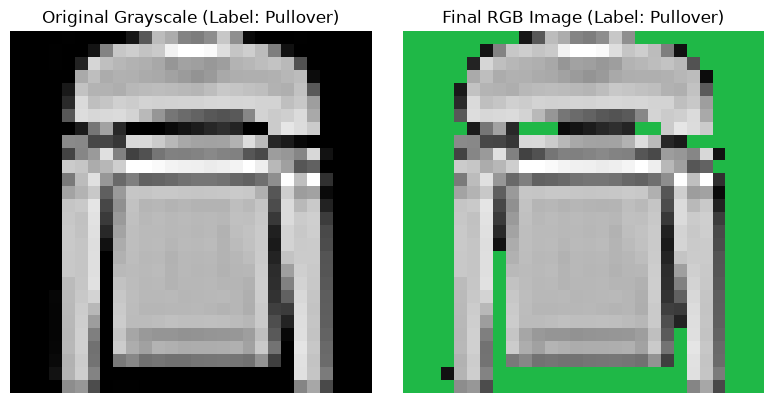

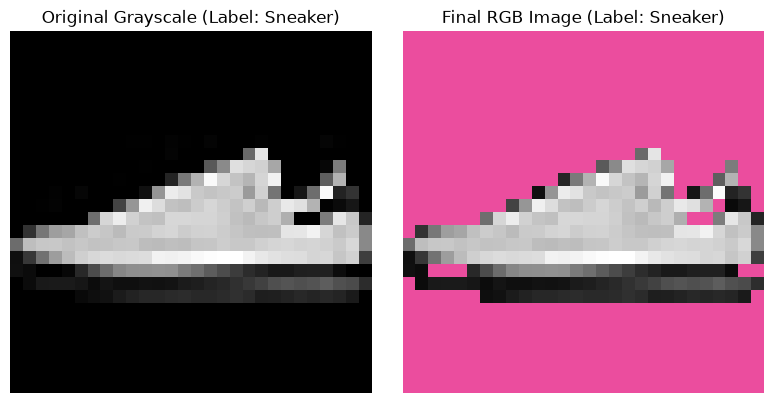

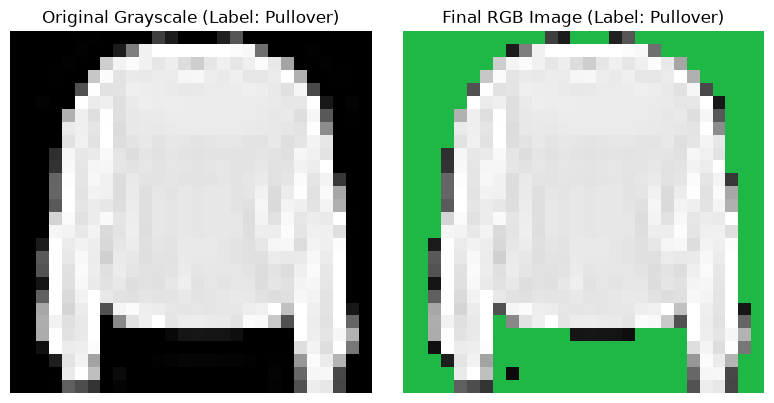

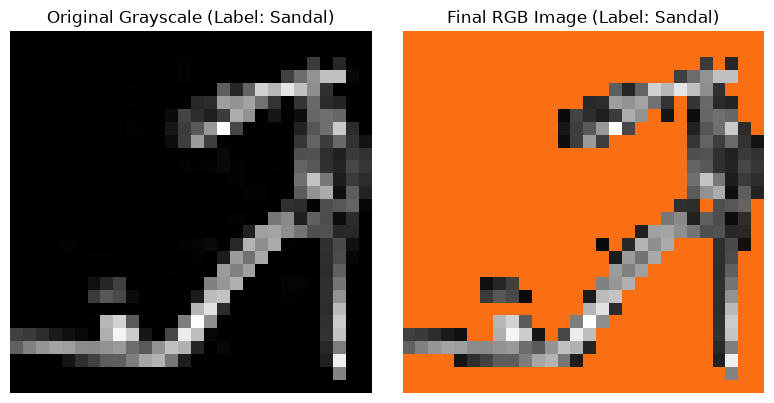

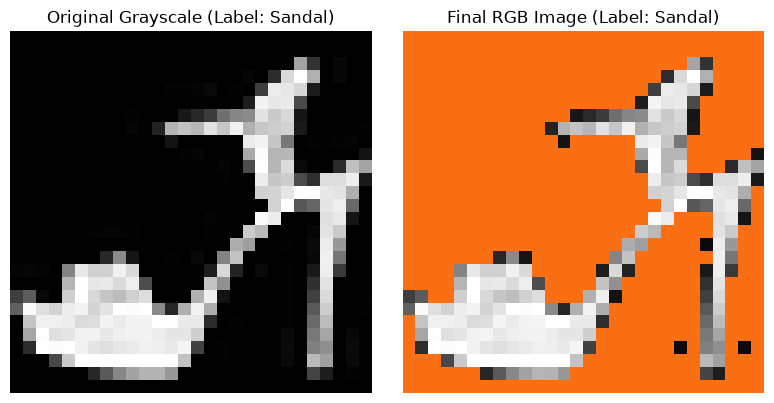

In [ ]:
for i in range(10):
    grayscale_image, label = dataset[i]
    grayscale_image = np.array(grayscale_image)
    rgb_image, label = inject_background_cue(
        grayscale_image, label, CLASS_COLORS, NEAR_ZERO_INTENSITY_THRESHOLD
    )

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    # Display the original grayscale image
    axes[0].imshow(grayscale_image, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title(f"Original Grayscale (Label: {CLASS_NAMES[label]})")
    axes[0].axis("off")

    # Display the final RGB image
    axes[1].imshow(rgb_image)
    axes[1].set_title(f"Final RGB Image (Label: {CLASS_NAMES[label]})")
    axes[1].axis("off")

    # Render the plot on screen
    plt.tight_layout()
    plt.show()

In [ ]:
transformed_images = []
transformed_image_labels = []

for raw_image, label in dataset:
    grayscale_image = np.array(raw_image, dtype=np.uint8)

    rgb_image, label = inject_background_cue(
        grayscale_image=grayscale_image,
        label=label,
        class_colors_array=CLASS_COLORS,
        near_zero_intensity_threshold=NEAR_ZERO_INTENSITY_THRESHOLD,
    )

    transformed_images.append(rgb_image)
    transformed_image_labels.append(label)

final_images_array = np.array(transformed_images)
final_labels_array = np.array(transformed_image_labels)

original_size = len(dataset)
assert (
    len(final_images_array) == original_size
), f"Image size mismatch: original_size={original_size}, final_images_array={len(final_images_array)}"
assert (
    len(final_labels_array) == original_size
), f"Label size mismatch: original_size={original_size}, final_labels_array={len(final_labels_array)}"

original_labels = np.array([label for _, label in dataset])
assert np.array_equal(
    original_labels, final_labels_array
), "Label mismatch between original and transformed datasets"

assert final_images_array.shape[1:] == (
    28,
    28,
    3,
), f"Image shape mismatch: expected (28, 28, 3), got {final_images_array.shape[1:]}"

print(
    "end=> Successfully transformed the dataset and verified the integrity of images and labels."
)

end=> Successfully transformed the dataset and verified the integrity of images and labels.


In [ ]:
# Saving the processed dataset as a .npy file
dataset_dict = {
    "images": final_images_array,
    "labels": final_labels_array,
}
processed_data_dir = f"../{config['dataset_param']['processed_data_dir']}"
if not os.path.exists(processed_data_dir):
    os.makedirs(processed_data_dir)
np.save(f"{processed_data_dir}/processed_dataset.npy", dataset_dict, allow_pickle=True)

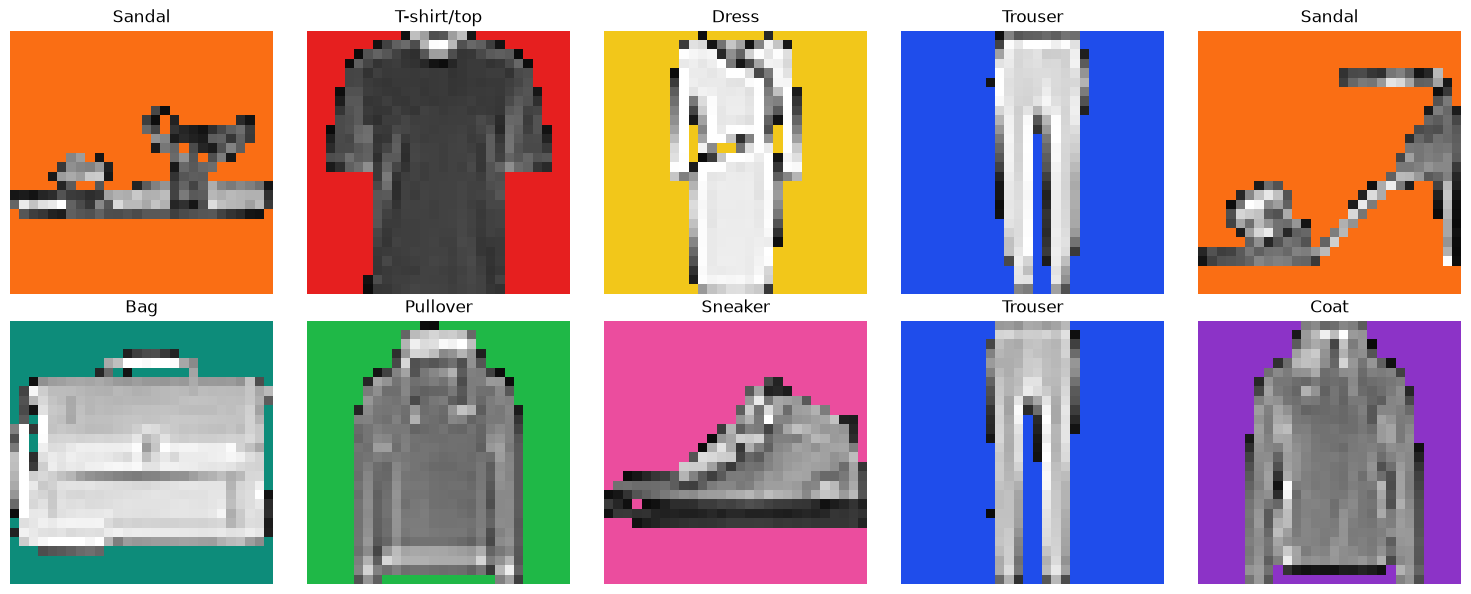

In [ ]:
# Rendering the last 10 images of the processed dataset
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

axes = axes.flatten()

for i in range(10):
    rgb_image = final_images_array[-(i + 1)]
    label = final_labels_array[-(i + 1)]

    ax = axes[i]

    ax.imshow(rgb_image)

    ax.set_title(f"{CLASS_NAMES[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()